# 03 · Modelação: treino e comparação de modelos

Neste notebook treinamos vários modelos de Machine Learning, comparamo-los de forma justa e escolhemos o melhor para estimar preços.

| | |
|---|---|
| **Entrada** | `data/processed/dados_limpos.csv` |
| **Saídas** | `models/modelo_final.joblib` · `reports/resultados_modelos.csv` · gráficos em `reports/figures/` |

### Conceitos-chave (explicados de forma simples)

**Treino e teste.** Um modelo aprende com exemplos (casas com preço conhecido). Para saber se aprendeu *mesmo*, testamo-lo com casas que **nunca viu** — tal como um exame com perguntas novas. Se o testássemos com as casas do treino, ele podia simplesmente tê-las "decorado".

**Validação cruzada repetida (25 testes).** Um único teste depende da sorte (que casas calharam no teste). Por isso:
1. Dividimos as casas em **5 grupos**;
2. Treinamos com 4 grupos e testamos no 5.º — rodando até cada grupo ser testado uma vez;
3. Baralhamos tudo e **repetimos 5 vezes**.

São **25 testes**. Reportamos a **média** e a **variação** (±) entre testes.

**Prever o logaritmo do preço.** Vimos no notebook 02 que os preços têm uma cauda longa. Prever o logaritmo faz o modelo pensar em **erros percentuais** (errar 50 mil € numa casa de 300 mil é grave; numa de 2 milhões, não). No fim, convertemos de volta para euros.

> Lembrete: o texto explica *o quê* e *porquê*; os comentários (`#`) dentro do código explicam *como*.

### Métricas usadas (sempre em euros, em casas que o modelo não viu)
| Métrica | O que significa |
|---|---|
| **MAE** | Erro médio absoluto: "em média, o modelo falha por X €" |
| **RMSE** | Parecido com o MAE, mas castiga mais os erros grandes |
| **R²** | Percentagem da variação dos preços que o modelo explica (0 a 1; quanto mais perto de 1, melhor) |
| **Erro % mediano** | Metade das casas tem um erro (em %) abaixo deste valor |
| **% casas com erro < 10%** | Quantas estimativas ficam a menos de 10% do preço real |

## 0. Preparação

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib        # para gravar o modelo treinado num ficheiro e voltar a abri-lo mais tarde

# scikit-learn (sklearn) é a biblioteca de Machine Learning mais usada em Python.
# Cada import traz uma "peça" que vamos usar:
from sklearn.base import clone                       # cria uma cópia "por treinar" de um modelo
from sklearn.model_selection import (RepeatedKFold, KFold, train_test_split,   # formas de dividir treino/teste
                                     cross_val_predict)   # prevê cada casa com um modelo que não a viu
from sklearn.compose import ColumnTransformer        # aplica preparações diferentes a colunas diferentes
from sklearn.pipeline import make_pipeline           # encadeia preparação + modelo num só objeto
from sklearn.impute import SimpleImputer             # preenche valores em falta
from sklearn.preprocessing import OneHotEncoder, StandardScaler   # categorias → 0/1; pôr números na mesma escala
from sklearn.linear_model import LinearRegression    # modelo 2
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor   # modelos 3 e 4
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score       # métricas
from sklearn.inspection import permutation_importance   # importância das variáveis
from xgboost import XGBRegressor                     # modelo 5 (biblioteca própria)
from lightgbm import LGBMRegressor                   # modelo 6 (biblioteca própria)

# Procurar a pasta do projeto: começamos na pasta atual (Path.cwd()) e subimos
# pasta a pasta (.parent) até encontrar a pasta 'src'. Assim o notebook funciona
# quer seja aberto a partir da pasta 'notebooks/', quer a partir da raiz do projeto.
RAIZ_PROJETO = Path.cwd()
while not (RAIZ_PROJETO / "src").is_dir() and RAIZ_PROJETO != RAIZ_PROJETO.parent:
    RAIZ_PROJETO = RAIZ_PROJETO.parent
sys.path.append(str(RAIZ_PROJETO))   # agora o Python consegue encontrar o módulo 'src'
from src.utils import (FICHEIRO_LIMPO, FICHEIRO_MODELO, RELATORIOS, SEMENTE, PRECO_MAX,
                       NUMERICAS, SIM_NAO, CATEGORIAS, VARIAVEIS, NOMES_BONITOS,
                       AZUL, TEXTO, TEXTO_2, aplicar_estilo, euros_curto, sem_rotulo,
                       guardar_figura, preparar_variaveis,
                       formatar_euros, num_pt, decimal_pt)

# Esconde um aviso técnico inofensivo do LightGBM, para o notebook ficar mais limpo
warnings.filterwarnings("ignore", message="X does not have valid feature names")
aplicar_estilo()

## 1. Âmbito: o mercado "normal"

Vimos no notebook 02 que as casas acima de **2,5 M€** são menos de 5% dos anúncios, mas muito diferentes e imprevisíveis. Por isso, **excluímo-las do treino**: assim deixam de "puxar" as previsões das casas normais para cima. Na **secção 8** testamos se esta decisão melhora mesmo o modelo.

**Decisão:** o modelo cobre apartamentos **até 2,5 M€**. Para casas acima disso, as estimativas não são fiáveis — e o notebook 04 avisa quando isso acontece.

In [2]:
dados = pd.read_csv(FICHEIRO_LIMPO)
n_total = len(dados)

# Ficamos só com as casas até ao limite de preço.
# reset_index(drop=True) renumera as linhas de 0 em diante (útil mais à frente,
# quando nos referimos às casas pela sua posição).
dados = dados[dados["preco"] <= PRECO_MAX].reset_index(drop=True)

# Acrescenta log_area e trata o "estado" em falta (função definida em src/utils.py)
dados = preparar_variaveis(dados)

print(f"Casas no âmbito (até {num_pt(PRECO_MAX/1e6)} M€): {len(dados)}")
print(f"Casas de luxo excluídas: {n_total - len(dados)} ({num_pt((n_total - len(dados))/n_total*100)}%)")

Casas no âmbito (até 2,5 M€): 1553
Casas de luxo excluídas: 70 (4,3%)


## 2. Variáveis usadas para prever

| Grupo | Variáveis |
|---|---|
| **Numéricas** | área, log(área), quartos, casas de banho, andar, latitude, longitude |
| **Sim/não** | elevador, empreendimento novo, terraço, piscina, jardim, ar condicionado, arrecadação, estacionamento |
| **Categorias** | freguesia, estado, tipo (apartamento, duplex, cobertura, estúdio) |

**Variáveis deixadas de fora de propósito:**
- `preco_m2` — é calculada a partir do preço. Usá-la seria "batota" (o modelo teria a resposta).
- `descida_preco_pct` — uma casa nova a avaliar ainda não tem histórico de descidas de preço.
- `bairro` — tem ~90 valores diferentes, muitos com 1–2 casas; a freguesia e as coordenadas já captam a localização.

In [3]:
# Convenção em Machine Learning:
#   X = as variáveis de entrada (o que o modelo usa para prever)
#   y = o alvo (o que queremos prever)
X = dados[VARIAVEIS]
y = np.log(dados["preco"])   # prevemos o LOGARITMO do preço (no fim convertemos de volta)

print(f"{X.shape[0]} casas × {X.shape[1]} variáveis")

1553 casas × 18 variáveis


## 3. Preparação dos dados para os modelos

Os modelos só trabalham com números e não aceitam (quase todos) valores em falta. Antes de treinar, cada modelo passa por uma **preparação automática**:

- **Números em falta** (ex.: andar desconhecido) → preenchidos com a **mediana**, e é criada uma coluna extra a dizer "este valor faltava". Assim o modelo pode aprender se a *falta* de informação, por si só, diz alguma coisa.
- **Categorias** (freguesia, estado, tipo) → transformadas em colunas 0/1 (*one-hot encoding*). Ex.: a coluna "freguesia = Arroios" vale 1 para casas em Arroios e 0 para as restantes.
- **Escala** → só para a Regressão Linear, os números são colocados na mesma escala (os modelos de árvores não precisam).

Esta preparação fica "colada" ao modelo num **pipeline**: é aprendida apenas com os dados de treino de cada teste, evitando que informação do teste "contamine" o treino.

In [4]:
def preparacao(escalar=False):
    '''Cria a "receita" de preparação dos dados.

    escalar=True só é usado na Regressão Linear (ver explicação acima).
    '''
    # Passos para as colunas numéricas e sim/não:
    #   SimpleImputer(strategy="median") → preenche os vazios com a mediana da coluna
    #   add_indicator=True               → cria colunas extra 0/1 a dizer "este valor faltava"
    passos_numericos = [SimpleImputer(strategy="median", add_indicator=True)]
    if escalar:
        # StandardScaler põe cada coluna com média 0 e desvio-padrão 1
        passos_numericos.append(StandardScaler())

    # ColumnTransformer aplica cada preparação ao seu grupo de colunas:
    #   ("nome", preparação, lista de colunas)
    # OneHotEncoder cria uma coluna 0/1 por cada valor das categorias.
    # handle_unknown="ignore": se aparecer uma freguesia nova (nunca vista no
    # treino), o modelo não dá erro — simplesmente põe 0 em todas as colunas.
    return ColumnTransformer([
        ("numericas", make_pipeline(*passos_numericos), NUMERICAS + SIM_NAO),
        ("categorias", OneHotEncoder(handle_unknown="ignore"), CATEGORIAS),
    ])

## 4. Os modelos

| # | Modelo | Ideia (em linguagem simples) |
|---|---|---|
| 1 | **Referência** | Área × preço/m² mediano da freguesia. Não é Machine Learning — é a "conta de cabeça" de um avaliador. Serve de **fasquia mínima**. |
| 2 | **Regressão Linear** | Encontra uma fórmula do tipo *preço = a × área + b × casas de banho + …*. Simples e fácil de interpretar, mas não capta interações (para ela, um m² vale o mesmo em todas as freguesias). |
| 3 | **Random Forest** | Centenas de **árvores de decisão** treinadas de forma independente, cada uma com uma amostra diferente das casas. A previsão é a **média** de todas. |
| 4 | **Gradient Boosting (scikit-learn)** | Árvores treinadas **em sequência**: cada nova árvore tenta **corrigir os erros** das anteriores. |
| 5 | **XGBoost** | A mesma técnica do 4, numa biblioteca dedicada e muito popular. As árvores crescem nível a nível. |
| 6 | **LightGBM** | A mesma técnica, da Microsoft. As árvores crescem pelo ramo que mais reduz o erro — rápido, mas exige cuidado com poucos dados. |

Uma **árvore de decisão** faz perguntas encadeadas sobre a casa ("área > 100 m²?", "fica em Santo António?"…) até chegar a uma estimativa.

As configurações escolhidas (nº de árvores, profundidade, etc.) — os chamados **hiperparâmetros** — são valores razoáveis e conservadores para um conjunto de dados pequeno. Não foram afinados: com ~1 500 casas, o ganho esperado é pequeno.

In [5]:
# Cada modelo é um "pipeline": preparação dos dados → modelo.
# make_pipeline(A, B) significa "aplica A e depois B".
# Guardamos os modelos num dicionário {nome: pipeline} para os percorrer num ciclo.
#
# Parâmetros comuns:
#   random_state=SEMENTE → resultados reproduzíveis
#   n_jobs=-1            → usa todos os processadores do computador (mais rápido)
modelos = {
    "Regressão Linear": make_pipeline(
        preparacao(escalar=True), LinearRegression()),

    # n_estimators = nº de árvores; min_samples_leaf = mínimo de casas em cada
    # "folha" (ponto final) da árvore — evita regras baseadas numa só casa
    "Random Forest": make_pipeline(
        preparacao(), RandomForestRegressor(
            n_estimators=300, min_samples_leaf=2, random_state=SEMENTE, n_jobs=-1)),

    # learning_rate = quanto cada árvore nova corrige as anteriores (pequeno = mais
    # cauteloso); max_iter = nº de árvores
    "Gradient Boosting (scikit-learn)": make_pipeline(
        preparacao(), HistGradientBoostingRegressor(
            learning_rate=0.05, max_iter=500, random_state=SEMENTE)),

    # max_depth = nº máximo de perguntas encadeadas em cada árvore;
    # min_child_weight = mínimo de "peso" (≈ casas) por folha;
    # subsample / colsample_bytree = % de casas / de variáveis que cada árvore vê
    # (introduz variedade entre árvores e reduz o risco de decorar)
    "XGBoost": make_pipeline(
        preparacao(), XGBRegressor(
            n_estimators=500, learning_rate=0.05, max_depth=5, min_child_weight=3,
            subsample=0.8, colsample_bytree=0.8, random_state=SEMENTE, n_jobs=-1)),

    # num_leaves = nº máximo de folhas por árvore; min_child_samples = mínimo de
    # casas por folha. Limitamo-los para o LightGBM não "decorar" casos particulares.
    # verbose=-1 → sem mensagens durante o treino
    "LightGBM": make_pipeline(
        preparacao(), LGBMRegressor(
            n_estimators=500, learning_rate=0.05, num_leaves=15, min_child_samples=10,
            subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
            random_state=SEMENTE, verbose=-1)),
}
REFERENCIA = "Referência (área × €/m² freguesia)"
ORDEM = [REFERENCIA, *modelos]

Duas funções de apoio: uma que calcula as métricas **em euros** (convertendo de volta do logaritmo) e outra que calcula a referência usando **apenas os dados de treino** de cada teste.

In [6]:
def calcular_metricas(real_log, previsto_log):
    '''Recebe preços reais e previstos (em logaritmo) e devolve as métricas em euros.'''
    # np.exp é o inverso do logaritmo: converte de volta para euros
    real, previsto = np.exp(real_log), np.exp(previsto_log)
    # Erro em % de cada casa: |previsto − real| / real × 100  (np.abs = valor absoluto)
    erro_pct = np.abs(previsto - real) / real * 100
    return {
        "MAE (€)": mean_absolute_error(real, previsto),
        "RMSE (€)": np.sqrt(mean_squared_error(real, previsto)),
        "R²": r2_score(real, previsto),
        "Erro % mediano": np.median(erro_pct),
        "% casas com erro < 10%": (erro_pct < 10).mean() * 100,
    }


def prever_referencia(idx_treino, idx_teste):
    '''Previsão da referência: área × €/m² mediano da freguesia.

    idx_treino / idx_teste são as posições das casas de treino e de teste.
    O €/m² de cada freguesia é calculado SÓ com as casas de treino (seria
    batota usar as casas do teste para calcular a mediana).
    '''
    treino = dados.loc[idx_treino]
    m2_por_freguesia = (treino["preco"] / treino["area_m2"]).groupby(treino["freguesia"]).median()
    m2_geral = (treino["preco"] / treino["area_m2"]).median()   # para freguesias sem casas no treino
    teste = dados.loc[idx_teste]
    # Para cada casa de teste, vai buscar o €/m² da sua freguesia
    m2 = teste["freguesia"].map(m2_por_freguesia).fillna(m2_geral)
    return np.log(teste["area_m2"] * m2).values

## 5. Avaliação: 25 testes

Este é o passo mais demorado (~1–2 minutos). Para cada um dos 25 testes, treinamos os 6 modelos com as mesmas casas e testamo-los nas mesmas casas — assim a comparação é **justa**.

Guardamos também as previsões da **1.ª repetição**: nessa ronda, cada casa é prevista exatamente uma vez, por um modelo que não a viu. Vamos usá-las para os gráficos e para calcular a margem de erro.

In [7]:
N_GRUPOS, N_REPETICOES = 5, 5

# RepeatedKFold gera as divisões treino/teste: 5 grupos × 5 repetições = 25 testes
divisoes = RepeatedKFold(n_splits=N_GRUPOS, n_repeats=N_REPETICOES, random_state=SEMENTE)

registos = []   # uma entrada por (teste, modelo) com as métricas obtidas

# Para cada modelo, um vetor de zeros (um lugar por casa) onde guardaremos as
# previsões da 1.ª repetição
previsoes_fora = {nome: np.zeros(len(dados)) for nome in ORDEM}

# divisoes.split(X) devolve, em cada volta, as posições das casas de treino e de teste
for teste, (idx_treino, idx_teste) in enumerate(divisoes.split(X)):

    # 1) Referência
    previsoes = {REFERENCIA: prever_referencia(idx_treino, idx_teste)}

    # 2) Cada modelo de ML:
    for nome, modelo in modelos.items():
        #   clone(modelo) → cópia nova, por treinar (cada teste começa do zero)
        #   .fit(X, y)     → TREINA o modelo com as casas de treino
        #   .iloc[posições] seleciona as linhas pela posição
        m = clone(modelo).fit(X.iloc[idx_treino], y.iloc[idx_treino])
        #   .predict(X)    → PREVÊ o preço (em log) das casas de teste
        previsoes[nome] = m.predict(X.iloc[idx_teste])

    # 3) Calcula as métricas de cada modelo neste teste e guarda-as
    for nome, prev in previsoes.items():
        registos.append({"teste": teste, "modelo": nome,
                         **calcular_metricas(y.iloc[idx_teste].values, prev)})
        if teste < N_GRUPOS:   # os primeiros 5 testes = 1.ª repetição
            previsoes_fora[nome][idx_teste] = prev

# Transforma a lista de registos numa tabela: 25 testes × 6 modelos = 150 linhas
resultados = pd.DataFrame(registos)
print(f"{resultados['teste'].nunique()} testes × {resultados['modelo'].nunique()} modelos concluídos.")

25 testes × 6 modelos concluídos.


## 6. Resultados

In [8]:
# Para cada modelo: média e desvio-padrão (variação) das métricas nos 25 testes.
# .loc[ORDEM] põe as linhas pela ordem em que apresentámos os modelos.
media = resultados.groupby("modelo").mean(numeric_only=True).drop(columns="teste").loc[ORDEM]
desvio = resultados.groupby("modelo").std(numeric_only=True).drop(columns="teste").loc[ORDEM]

# Tabela "bonita" para leitura: cada célula no formato "média ± variação".
# [... for m, s in zip(...)] é uma "list comprehension": cria uma lista
# aplicando a mesma formatação a cada par (média, desvio).
tabela = pd.DataFrame({
    "MAE": [f"{m/1000:.0f} mil € ± {s/1000:.0f}" for m, s in zip(media["MAE (€)"], desvio["MAE (€)"])],
    "RMSE": [f"{m/1000:.0f} mil € ± {s/1000:.0f}" for m, s in zip(media["RMSE (€)"], desvio["RMSE (€)"])],
    "R²": [f"{num_pt(m, 2)} ± {num_pt(s, 2)}" for m, s in zip(media["R²"], desvio["R²"])],
    "Erro % mediano": [f"{num_pt(m)}% ± {num_pt(s)}" for m, s in zip(media["Erro % mediano"], desvio["Erro % mediano"])],
    "Casas com erro < 10%": [f"{m:.0f}%" for m in media["% casas com erro < 10%"]],
}, index=ORDEM)

# Grava as métricas em reports/ (são agregadas, por isso podem ser publicadas)
RELATORIOS.mkdir(parents=True, exist_ok=True)
pd.concat({"media": media, "desvio": desvio}, axis=1).round(3).to_csv(
    RELATORIOS / "resultados_modelos.csv", encoding="utf-8-sig")
tabela

,MAE,RMSE,R²,Erro % mediano,Casas com erro < 10%
Referência (área × €/m² freguesia),190 mil € ± 13,286 mil € ± 20,"0,65 ± 0,04","17,6% ± 1,4",32%
Regressão Linear,142 mil € ± 10,222 mil € ± 16,"0,79 ± 0,02","12,3% ± 0,8",42%
Random Forest,131 mil € ± 10,213 mil € ± 15,"0,80 ± 0,02","10,1% ± 1,0",50%
Gradient Boosting (scikit-learn),126 mil € ± 11,202 mil € ± 17,"0,82 ± 0,02","10,2% ± 0,9",49%
XGBoost,123 mil € ± 10,197 mil € ± 16,"0,83 ± 0,02","9,8% ± 1,0",51%
LightGBM,123 mil € ± 10,197 mil € ± 17,"0,83 ± 0,02","10,0% ± 1,0",50%


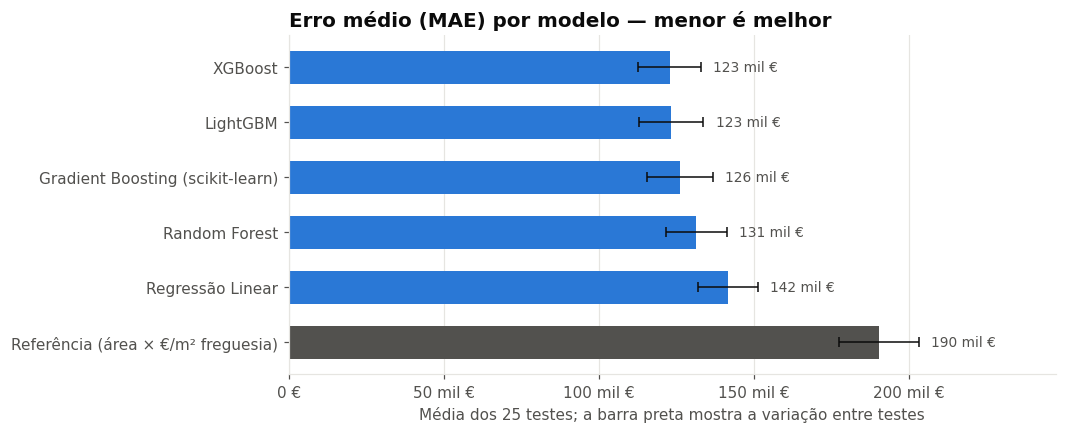

In [9]:
fig, ax = plt.subplots(figsize=(9, 4))

# Ordena os modelos do pior (maior erro) para o melhor, para o melhor ficar no topo
ordem_grafico = media["MAE (€)"].sort_values(ascending=False).index

# A referência fica a cinzento, para se distinguir dos modelos de ML
cores = [TEXTO_2 if nome == REFERENCIA else AZUL for nome in ordem_grafico]

# xerr desenha a "barra de erro" (variação entre testes) na ponta de cada barra
ax.barh(ordem_grafico, media.loc[ordem_grafico, "MAE (€)"], color=cores, height=0.6,
        xerr=desvio.loc[ordem_grafico, "MAE (€)"], error_kw={"ecolor": TEXTO, "capsize": 3, "lw": 1})
for i, nome in enumerate(ordem_grafico):
    ax.text(media.loc[nome, "MAE (€)"] + desvio.loc[nome, "MAE (€)"] + 4000, i,
            f"{media.loc[nome, 'MAE (€)']/1000:.0f} mil €", va="center", color=TEXTO_2, fontsize=9)
ax.xaxis.set_major_formatter(euros_curto)
ax.set_xlim(0, media["MAE (€)"].max() * 1.3)
ax.set_title("Erro médio (MAE) por modelo — menor é melhor")
ax.set_xlabel("Média dos 25 testes; a barra preta mostra a variação entre testes")
ax.grid(axis="y", visible=False)
guardar_figura(fig, "05_comparacao_modelos.png")
plt.show()

**Leitura:**
- **Todos os modelos de Machine Learning batem a referência**, e com margem: estão a aprender algo útil para além de "área × preço da zona".
- **Os modelos de árvores (3 a 6) ganham à Regressão Linear** — conseguem captar interações (ex.: um m² extra vale mais em Santo António do que em Marvila).
- **As três versões de Gradient Boosting e a Random Forest estão próximas.** A diferença entre elas é menor do que a variação entre testes (as barras pretas sobrepõem-se). Será que há um vencedor real? Vemos isso a seguir.

## 7. Comparação frente a frente

A variação "±" mistura duas coisas: testes mais fáceis e mais difíceis (afeta **todos** os modelos) e diferenças reais entre modelos. Uma forma mais precisa de comparar dois modelos é pô-los **frente a frente no mesmo teste** e contar quantas vezes cada um ganha.

Se um modelo ganha, por exemplo, 23 de 25 testes, a vantagem é consistente — mesmo que pequena. Se ganha ~12–13 de 25, é uma moeda ao ar.

In [10]:
# .pivot reorganiza a tabela: uma linha por teste, uma coluna por modelo, com o MAE
mae_por_teste = resultados.pivot(index="teste", columns="modelo", values="MAE (€)")

# O melhor modelo é o que tem menor MAE médio (excluindo a referência).
# .idxmin() devolve o NOME da linha com o valor mínimo.
melhor = media.drop(index=REFERENCIA)["MAE (€)"].idxmin()

# Para cada outro modelo:
#  - .gt(..., axis=0) compara teste a teste: True quando o outro modelo errou MAIS
#    do que o melhor; .sum() conta esses testes
#  - .sub(..., axis=0) calcula a diferença de erro em cada teste; .mean() faz a média
frente_a_frente = pd.DataFrame({
    "testes ganhos pelo melhor (de 25)": mae_por_teste.gt(mae_por_teste[melhor], axis=0).sum(),
    "vantagem média do melhor": mae_por_teste.sub(mae_por_teste[melhor], axis=0).mean().map(
        lambda v: f"{num_pt(v/1000)} mil €"),
}).drop(index=melhor).loc[[m for m in ORDEM if m != melhor]]

print(f"Melhor modelo (menor erro médio): {melhor}\n")
frente_a_frente

Melhor modelo (menor erro médio): XGBoost



,testes ganhos pelo melhor (de 25),vantagem média do melhor
modelo,,
Referência (área × €/m² freguesia),25,"67,5 mil €"
Regressão Linear,25,"18,8 mil €"
Random Forest,25,"8,6 mil €"
Gradient Boosting (scikit-learn),23,"3,3 mil €"
LightGBM,15,"0,6 mil €"


**Leitura:** o modelo escolhido ganha de forma **muito consistente** à referência, à Regressão Linear e à Random Forest, e também ao Gradient Boosting do scikit-learn (por pouco, mas quase sempre). Já entre **XGBoost e LightGBM** a disputa é equilibrada — na prática, um **empate técnico**: qualquer um dos dois seria uma boa escolha.

## 8. Confirmação: excluir o luxo ajudou?

Na secção 1 decidimos deixar de fora as casas acima de 2,5 M€. Aqui **testamos** essa decisão, em vez de simplesmente confiarmos nela:

1. Fazemos 25 testes (como na secção 5), mas agora com **todas** as casas, incluindo o luxo;
2. Em cada teste treinamos o modelo escolhido **duas vezes**:
   - **(a)** com todas as casas de treino (incluindo o luxo);
   - **(b)** só com as casas de treino até 2,5 M€;
3. Comparamos as duas versões **apenas nas casas de teste até 2,5 M€** — o mercado que queremos prever.

Se a versão (b) errar menos, confirma-se que o luxo "atrapalha" as previsões das casas normais.

In [11]:
# Voltamos a ler TODAS as casas limpas (incluindo as de luxo)
todas = preparar_variaveis(pd.read_csv(FICHEIRO_LIMPO))
X_todas, y_todas = todas[VARIAVEIS], np.log(todas["preco"])

# normal = coluna True/False: True para as casas até 2,5 M€.
# .values transforma-a numa lista simples, para a podermos usar com posições.
normal = (todas["preco"] <= PRECO_MAX).values

erros = {"(a) com luxo no treino": [], "(b) sem luxo no treino": []}
divisoes_luxo = RepeatedKFold(n_splits=N_GRUPOS, n_repeats=N_REPETICOES, random_state=SEMENTE)

for idx_treino, idx_teste in divisoes_luxo.split(X_todas):
    # idx_teste[normal[idx_teste]] → das casas de teste, fica só com as que são "normais"
    teste_normal = idx_teste[normal[idx_teste]]
    treino_sem_luxo = idx_treino[normal[idx_treino]]
    real = np.exp(y_todas.iloc[teste_normal])          # preços reais, em euros

    # (a) treino com todas as casas de treino
    m_a = clone(modelos[melhor]).fit(X_todas.iloc[idx_treino], y_todas.iloc[idx_treino])
    erros["(a) com luxo no treino"].append(
        mean_absolute_error(real, np.exp(m_a.predict(X_todas.iloc[teste_normal]))))

    # (b) treino só com as casas até 2,5 M€
    m_b = clone(modelos[melhor]).fit(X_todas.iloc[treino_sem_luxo], y_todas.iloc[treino_sem_luxo])
    erros["(b) sem luxo no treino"].append(
        mean_absolute_error(real, np.exp(m_b.predict(X_todas.iloc[teste_normal]))))

erros = pd.DataFrame(erros)   # uma linha por teste, uma coluna por versão
mae_a, mae_b = erros.mean()   # erro médio de cada versão nos 25 testes
reducao_luxo = 1 - mae_b / mae_a
vitorias_b = (erros["(b) sem luxo no treino"] < erros["(a) com luxo no treino"]).sum()

print("Erro médio (MAE) nas casas de teste até 2,5 M€:")
print(f"  (a) treino com luxo: {formatar_euros(mae_a)}")
print(f"  (b) treino sem luxo: {formatar_euros(mae_b)}")
print(f"Excluir o luxo reduz o erro em {num_pt(reducao_luxo*100)}% "
      f"— a versão (b) ganhou {vitorias_b} de {len(erros)} testes.")

Erro médio (MAE) nas casas de teste até 2,5 M€:
  (a) treino com luxo: 133 222 €
  (b) treino sem luxo: 124 463 €
Excluir o luxo reduz o erro em 6,6% — a versão (b) ganhou 24 de 25 testes.


**Leitura:** a decisão confirma-se. Treinar sem as casas de luxo reduz o erro médio nas casas normais em **cerca de 7%**, e essa vantagem aparece em **24 dos 25 testes** — não é sorte. As casas muito caras são poucas e muito diferentes entre si; quando entram no treino, "puxam" para cima as previsões das casas normais.

## 9. Margem de erro

Uma estimativa sem margem pode enganar. Usando as previsões em casas que o modelo **não viu**, calculamos entre que valores ficou o preço real em **80% dos casos**.

In [12]:
# Para cada casa: preço real ÷ estimativa (ex.: 1,10 = o preço real foi 10% acima)
razao = np.exp(y.values) / np.exp(previsoes_fora[melhor])

# Os percentis 10 e 90 delimitam os 80% de casos centrais:
# 10% das casas ficaram abaixo do limite inferior e 10% acima do superior
limite_inferior, limite_superior = np.percentile(razao, [10, 90])

print(f"Em 80% das casas, o preço real ficou entre {limite_inferior:.0%} e {limite_superior:.0%} da estimativa.")
print(f"Exemplo: para uma estimativa de 500 mil €, o intervalo provável é "
      f"{500*limite_inferior:.0f} – {500*limite_superior:.0f} mil €.")

Em 80% das casas, o preço real ficou entre 80% e 127% da estimativa.
Exemplo: para uma estimativa de 500 mil €, o intervalo provável é 401 – 633 mil €.


## 10. Previsto vs real

Cada ponto é uma casa, prevista por um modelo que **não a viu** durante o treino. Quanto mais perto da linha tracejada, melhor a previsão.

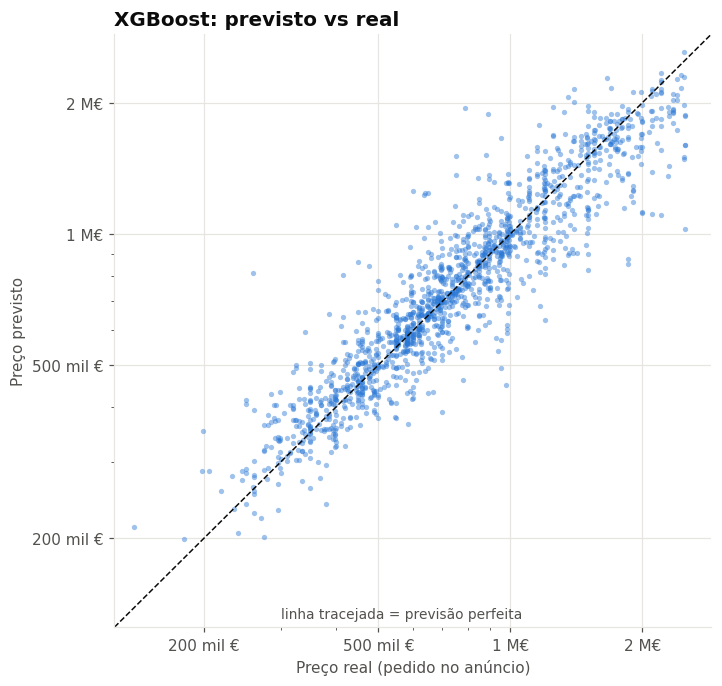

In [13]:
# Converter de logaritmo para euros
real, previsto = np.exp(y.values), np.exp(previsoes_fora[melhor])

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(real, previsto, s=12, color=AZUL, alpha=0.45, linewidths=0)
limites = [min(real.min(), previsto.min()) * 0.9, max(real.max(), previsto.max()) * 1.1]
# Linha diagonal (previsto = real): onde estariam os pontos se o modelo fosse perfeito
ax.plot(limites, limites, color=TEXTO, linewidth=1, linestyle="--")
ax.text(limites[0] * 2.4, limites[0] * 1.05, "linha tracejada = previsão perfeita", color=TEXTO_2, fontsize=9)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlim(limites); ax.set_ylim(limites)
for eixo in (ax.xaxis, ax.yaxis):
    eixo.set_major_formatter(euros_curto)
    eixo.set_minor_formatter(sem_rotulo)
ax.set_xticks([200e3, 500e3, 1e6, 2e6]); ax.set_yticks([200e3, 500e3, 1e6, 2e6])
ax.set_xlabel("Preço real (pedido no anúncio)"); ax.set_ylabel("Preço previsto")
ax.set_title(f"{melhor}: previsto vs real")
guardar_figura(fig, "06_previsto_vs_real.png")
plt.show()

**Leitura:** os pontos seguem bem a diagonal. A nuvem "abre" um pouco nas casas mais caras — o modelo tem mais dificuldade aí, porque há menos exemplos e mais variedade.

## 11. Que variáveis mais influenciam a previsão?

Usamos a **importância por permutação**: pegamos numa variável, **baralhamos** os seus valores entre as casas (destruindo a informação que ela tem) e medimos **quanto pioram as previsões**. Quanto mais piora, mais o modelo depende dessa variável.

Fazemos isto num teste à parte (80% treino / 20% teste).

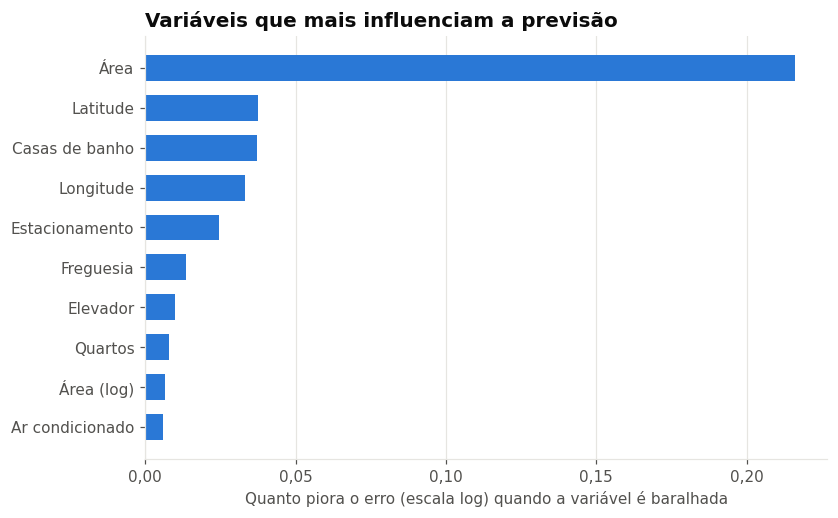

In [14]:
# train_test_split divide as casas: 80% treino, 20% teste (test_size=0.2)
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.2, random_state=SEMENTE)
modelo_importancia = clone(modelos[melhor]).fit(X_treino, y_treino)

# permutation_importance baralha cada variável 10 vezes (n_repeats=10) e mede
# quanto o erro aumenta em média
resultado = permutation_importance(modelo_importancia, X_teste, y_teste, n_repeats=10,
                                   random_state=SEMENTE, scoring="neg_mean_absolute_error")

# Uma "Series" é uma coluna com nomes: aqui, nome da variável → importância
importancia = pd.Series(resultado.importances_mean, index=VARIAVEIS).sort_values(ascending=False)

# As 10 mais importantes; [::-1] inverte a ordem (para a mais importante ficar no topo)
top = importancia.head(10)[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh([NOMES_BONITOS[v] for v in top.index], top.values, color=AZUL, height=0.65)
ax.set_title("Variáveis que mais influenciam a previsão")
ax.set_xlabel("Quanto piora o erro (escala log) quando a variável é baralhada")
ax.xaxis.set_major_formatter(decimal_pt)   # vírgula decimal no eixo
ax.grid(axis="y", visible=False)
guardar_figura(fig, "07_importancia_variaveis.png")
plt.show()

A importância por permutação tem uma limitação: quando duas variáveis dão **a mesma informação**, baralhar só uma delas quase não prejudica o modelo, porque a outra "compensa". É o caso da **freguesia** e das **coordenadas** — ambas dizem onde fica a casa.

Por isso fazemos um segundo teste, por **grupos de variáveis**: retiramos um grupo, **voltamos a treinar** o modelo sem ele e medimos quanto o erro aumenta (5 testes).

In [15]:
def modelo_so_com(numericas, categorias):
    '''O modelo escolhido, mas a usar só as variáveis indicadas.'''
    preparacao_reduzida = ColumnTransformer([
        ("numericas", SimpleImputer(strategy="median", add_indicator=True), numericas + SIM_NAO),
        ("categorias", OneHotEncoder(handle_unknown="ignore"), categorias),
    ])
    # modelos[melhor][-1] é o último passo do pipeline, ou seja, o próprio modelo (sem a preparação)
    return make_pipeline(preparacao_reduzida, clone(modelos[melhor][-1]))

# Lista de variáveis numéricas sem a latitude e a longitude
sem_coordenadas = [v for v in NUMERICAS if v not in ("latitude", "longitude")]

cenarios = {
    "Todas as variáveis":                       (NUMERICAS, CATEGORIAS),
    "Sem freguesia":                            (NUMERICAS, ["estado", "tipo"]),
    "Sem coordenadas (latitude e longitude)":   (sem_coordenadas, CATEGORIAS),
    "Sem localização (freguesia + coordenadas)": (sem_coordenadas, ["estado", "tipo"]),
}

cinco_testes = KFold(n_splits=5, shuffle=True, random_state=SEMENTE)
linhas = []
for nome, (numericas, categorias) in cenarios.items():
    # cross_val_predict: cada casa é prevista por um modelo treinado sem ela (5 testes)
    previsto = cross_val_predict(modelo_so_com(numericas, categorias), X, y, cv=cinco_testes)
    linhas.append({"cenário": nome, "MAE": mean_absolute_error(np.exp(y), np.exp(previsto))})

grupos_variaveis = pd.DataFrame(linhas).set_index("cenário")
grupos_variaveis["aumento do erro"] = grupos_variaveis["MAE"] / grupos_variaveis.loc["Todas as variáveis", "MAE"] - 1

grupos_variaveis.style.format({
    "MAE": formatar_euros,
    "aumento do erro": lambda v: f"{v*100:+.1f}%".replace(".", ","),
})

,MAE,aumento do erro
cenário,,
Todas as variáveis,123 160 €,"+0,0%"
Sem freguesia,124 065 €,"+0,7%"
Sem coordenadas (latitude e longitude),127 896 €,"+3,8%"
Sem localização (freguesia + coordenadas),155 966 €,"+26,6%"


**Leitura:**
- A **área** é, de longe, a variável mais importante.
- A **localização** é o segundo grande fator — mas o gráfico de permutação **subestima-a**. No teste por grupos, retirar só a freguesia (+0,7%) ou só as coordenadas (+3,8%) quase não muda o erro, porque uma "compensa" a outra; mas **retirar as duas aumenta o erro em cerca de 27%**. Entre as duas, as coordenadas são as mais úteis, porque distinguem zonas dentro da mesma freguesia.
- Seguem-se as **casas de banho** e o **estacionamento**.
- **Piscina, terraço e jardim pesam pouco.** No notebook 02 vimos que estão associados a preços mais altos, mas: (1) faltam em ~40% dos anúncios e (2) o seu efeito é, em boa parte, captado pela área, pela localização e pelo estado. Quando o modelo já sabe isso, o extra acrescenta pouco.

## 12. Treinar o modelo final e gravar

Depois de escolhido o modelo, treinamo-lo uma última vez com **todas** as casas do âmbito (mais dados = melhor modelo) e gravamo-lo juntamente com a informação necessária para fazer previsões: a lista de variáveis, a margem de erro e o limite de preço.

In [16]:
# Treino final com TODAS as casas (X, y completos)
modelo_final = clone(modelos[melhor]).fit(X, y)

# joblib.dump grava num ficheiro tudo o que for preciso para fazer previsões mais tarde:
# o modelo treinado e a informação de contexto (variáveis, margem, limite de preço)
FICHEIRO_MODELO.parent.mkdir(parents=True, exist_ok=True)
joblib.dump({
    "modelo": modelo_final,
    "nome": melhor,
    "variaveis": VARIAVEIS,
    "margem": (limite_inferior, limite_superior),
    "preco_max": PRECO_MAX,
    "n_casas_treino": len(dados),
}, FICHEIRO_MODELO)
print(f"Modelo '{melhor}' gravado em models/{FICHEIRO_MODELO.name}")

Modelo 'XGBoost' gravado em models/modelo_final.joblib


## Conclusões

- **O melhor modelo** (Gradient Boosting — XGBoost/LightGBM) erra em média **~123 mil €**, explica **~83%** da variação dos preços (R²) e acerta a menos de 10% em **cerca de metade** das casas.
- Face à **referência simples**, o erro médio desce **~35%**.
- **Os fatores que mais pesam** são a área e a localização (sem freguesia e coordenadas, o erro sobe ~27%).
- **Excluir o luxo** (> 2,5 M€) do treino reduz o erro nas casas normais em ~7% (confirmado em 24 de 25 testes).
- As **três implementações de Gradient Boosting** dão resultados muito próximos; o XGBoost e o LightGBM ganham consistentemente à versão do scikit-learn, mas por pouco (~2–3%).
- **Margem:** em 80% dos casos, o preço real fica aproximadamente entre **80% e 127%** da estimativa.

### Limitações
- O modelo estima o **preço pedido** no anúncio, **não** o preço de escritura (normalmente mais baixo).
- Não cobre o **luxo** (> 2,5 M€) e é menos fiável em freguesias com **poucos anúncios**.
- Faltam variáveis relevantes: **idade do imóvel**, **certificado energético**, **vistas**, **qualidade dos acabamentos**.
- A amostra é **uma única recolha** (um dia) e pode não representar todo o mercado de Lisboa.
- **Resultados ligeiramente otimistas:** frações semelhantes do mesmo prédio (comuns em empreendimentos novos) podem ficar uma no treino e outra no teste, o que facilita a previsão. Num teste em que as casas do mesmo prédio ficam sempre do mesmo lado, o erro médio sobe de ~123 para ~132 mil €.

### Próximos passos
1. **Recolher mais dados** ao longo do tempo (o que mais melhora o modelo).
2. Acrescentar variáveis em falta (ex.: palavras-chave da descrição, dados do INE por freguesia).
3. Comparar com **preços de transação** do INE para medir a diferença entre preço pedido e preço de venda.

➡️ **Próximo passo:** `04_previsao.ipynb`